# Machine Learning-Based Buyer Segmentation and Investment Profiling for Real Estate Market Intelligence
### Collaborators: **Unified Mentor** & **Parcl Co. Limited**
### Domain: **Financial Analytics & Real Estate Market Intelligence**

---

## 📌 Executive Summary & Project Context

Real estate platforms operate in diverse customer markets where buyers exhibit starkly distinct behaviors:
- **Individual Home Buyers:** Seeking personal primary dwellings, often reliant on mortgage financing.
- **Institutional / Corporate Buyers:** Companies acquiring bulk multi-unit portfolios across towers.
- **International / Global Investors:** Cross-border capital allocators seeking inflation hedges.
- **Luxury Investors:** High satisfaction, high average purchase price, prestige-seeking clients.
- **First-Time Buyers:** Younger demographic requiring tailored financing and rate assistance.

Without machine learning segmentation, platforms treat all buyers identically, leading to:
- **Inefficient marketing spend**
- **Generic property recommendations**
- **Missed high-yield investment opportunities**

### Methodological Workflow:
1. **Step 1 – Data Cleaning:** Merging 10,000 property listing transactions with 2,000 client records, cleaning currency values, deriving age, and standardizing dates.
2. **Step 2 – Feature Encoding:** Label Encoding binary features and One-Hot Encoding nominal categoricals.
3. **Step 3 – Feature Scaling:** StandardScaler normalization to ensure balanced Euclidean distances.
4. **Step 4 – Clustering Model Selection:** Benchmarking K-Means++ and Hierarchical Agglomerative Clustering.
5. **Step 5 – Optimal Cluster Selection:** Validating $K = 4$ via the Elbow Method (WCSS) and Silhouette Coefficients.
6. **Step 6 – Cluster Interpretation & Actionable Intelligence:** Mapping segments to PRD archetypes (C1: Global Investors, C2: First-Time Buyers, C3: Corporate Buyers, C4: Luxury Investors) and defining strategic business playbooks.

---


In [1]:
# 1. Environment Setup & Core Libraries
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Scaling
from sklearn.preprocessing import StandardScaler

# Clustering & Metrics
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score

# Dimensionality Reduction
from sklearn.decomposition import PCA

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['figure.dpi'] = 110

print("Environment configured successfully!")


Environment configured successfully!


## Step 1 – Data Cleaning & Integration

### Raw Datasets Ingested:
1. `raw_listings.csv`: 10,000 transaction records tracking listing status, square footage, tower numbers, and sale prices.
2. `raw_clients.csv`: 2,000 customer demographic profiles.

### Tasks Performed:
- Clean and convert formatted currency strings (`$300,385.62` $\rightarrow$ `300385.62`).
- Aggregate transaction metrics per buyer (`total_investment`, `units_purchased`, `avg_price_per_unit`, `avg_sqft`, `office_ratio`).
- Relational merge on `client_id = client_ref`.
- Parse mixed birth date formats and compute chronological `age`.
- Standardize categorical labels (`Home` $\rightarrow$ `Personal use`, `Company` $\rightarrow$ `Corporate`).


In [2]:
# Step 1: Data Cleaning Execution
listings = pd.read_csv('../data/raw_listings.csv')
clients = pd.read_csv('../data/raw_clients.csv')

# 1. Clean listing price
listings['sale_price_clean'] = listings['sale_price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

# 2. Aggregate sold units per buyer
sold = listings[listings['listing_status'] == 'Sold']
buyer_agg = sold.groupby('client_ref').agg(
    total_investment=('sale_price_clean', 'sum'),
    avg_price_per_unit=('sale_price_clean', 'mean'),
    units_purchased=('listing_id', 'count'),
    total_sqft=('floor_area_sqft', 'sum'),
    avg_sqft=('floor_area_sqft', 'mean'),
    office_ratio=('unit_category', lambda x: (x == 'Office').mean())
).reset_index()

# 3. Merge with Clients
df_clean = pd.merge(clients, buyer_agg, left_on='client_id', right_on='client_ref', how='left')
df_clean.drop(columns=['client_ref'], inplace=True)

# 4. Parse DOB & Calculate Age
df_clean['dob_parsed'] = pd.to_datetime(df_clean['date_of_birth'], format='mixed', errors='coerce')
reference_year = 2026
df_clean['age'] = reference_year - df_clean['dob_parsed'].dt.year

# 5. Normalize labels as per PRD
df_clean['client_type_norm'] = df_clean['client_type'].replace({'Company': 'Corporate', 'Individual': 'Individual'})
df_clean['acquisition_purpose_norm'] = df_clean['acquisition_purpose'].replace({'Home': 'Personal use', 'Investment': 'Investment'})
df_clean['gender_norm'] = df_clean['gender'].replace({'M': 'Male', 'F': 'Female'})

print(f"Cleaned Merged Dataset Shape: {df_clean.shape}")
print(f"Missing Values: {df_clean.isnull().sum().sum()}")
df_clean[['client_id', 'client_type_norm', 'age', 'country', 'acquisition_purpose_norm', 'loan_applied', 'satisfaction_score', 'total_investment', 'units_purchased']].head()


Cleaned Merged Dataset Shape: (2000, 23)
Missing Values: 0


,client_id,client_type_norm,age,country,acquisition_purpose_norm,loan_applied,satisfaction_score,total_investment,units_purchased
0,C0001,Individual,58,USA,Personal use,Yes,4,1246764.72,4
1,C0002,Individual,64,USA,Personal use,No,1,1841095.93,5
2,C0003,Individual,67,USA,Personal use,Yes,4,1661457.59,5
3,C0004,Individual,67,USA,Personal use,No,5,1608263.51,6
4,C0005,Corporate,50,USA,Investment,No,5,3653385.38,13


## Step 2 – Feature Encoding

We convert non-numeric attributes using the two techniques mandated in the PRD:
1. **Label / Binary Encoding:**
   - `client_type`: `Corporate` = 1, `Individual` = 0
   - `acquisition_purpose`: `Investment` = 1, `Personal use` = 0
   - `loan_applied`: `Yes` = 1, `No` = 0
   - `gender`: `Male` = 1, `Female` = 0
   - `is_international`: `Non-USA` = 1, `USA` = 0
2. **One-Hot Encoding:**
   - `referral_channel`: `Website`, `Agency`, `Client`
   - `country`: One-Hot indicators across buyer nations
   - `macro_region`: Continental macro-zones


In [3]:
# Step 2: Feature Encoding Execution
encoded_df = df_clean.copy()

# Binary mappings
encoded_df['client_type_encoded'] = (encoded_df['client_type_norm'] == 'Corporate').astype(int)
encoded_df['acquisition_purpose_encoded'] = (encoded_df['acquisition_purpose_norm'] == 'Investment').astype(int)
encoded_df['loan_applied_encoded'] = (encoded_df['loan_applied'] == 'Yes').astype(int)
encoded_df['gender_encoded'] = (encoded_df['gender_norm'] == 'Male').astype(int)
encoded_df['is_international'] = (encoded_df['country'] != 'USA').astype(int)

# One-Hot Encoding for Channel and Country
channel_dummies = pd.get_dummies(encoded_df['referral_channel'], prefix='channel', drop_first=True, dtype=int)
country_dummies = pd.get_dummies(encoded_df['country'], prefix='country', drop_first=True, dtype=int)

# Regional Macro-zones
region_macro_map = {
    'California': 'North America - West', 'Nevada': 'North America - West', 'Oregon': 'North America - West',
    'Washington': 'North America - West', 'Arizona': 'North America - West', 'Utah': 'North America - West',
    'Colorado': 'North America - Central', 'Texas': 'North America - Central', 'New York': 'North America - East',
    'Virginia': 'North America - East', 'Florida': 'North America - East', 'Georgia': 'North America - East',
    'Ohio': 'North America - Central', 'British Columbia': 'Canada', 'Alberta': 'Canada', 'Ontario': 'Canada', 'Quebec': 'Canada',
    'England': 'UK & Ireland', 'Scotland': 'UK & Ireland', 'Wales': 'UK & Ireland', 'Northern Ireland': 'UK & Ireland',
    'Berlin': 'Western Europe', 'Bavaria': 'Western Europe', 'Hamburg': 'Western Europe', 'Hesse': 'Western Europe',
    'North Rhine-Westphalia': 'Western Europe', 'Ile-de-France': 'Western Europe', 'Provence': 'Western Europe',
    'Brittany': 'Western Europe', 'Normandy': 'Western Europe', 'Occitanie': 'Western Europe',
    'Brussels': 'Western Europe', 'Flanders': 'Western Europe', 'Wallonia': 'Western Europe',
    'Mexico City': 'Latin America', 'Jalisco': 'Latin America', 'Nuevo Leon': 'Latin America', 'Puebla': 'Latin America', 'Baja California': 'Latin America',
    'New South Wales': 'Asia-Pacific', 'Victoria': 'Asia-Pacific', 'Queensland': 'Asia-Pacific', 'Western Australia': 'Asia-Pacific', 'South Australia': 'Asia-Pacific',
    'Saint Petersburg': 'Eastern Europe', 'Moscow Oblast': 'Eastern Europe', 'Krasnodar Krai': 'Eastern Europe', 'Novosibirsk': 'Eastern Europe', 'Tatarstan': 'Eastern Europe',
    'Capital Region': 'Nordics', 'North Denmark': 'Nordics', 'Southern Denmark': 'Nordics', 'Zealand': 'Nordics'
}
encoded_df['macro_region'] = encoded_df['region'].map(region_macro_map).fillna('Other')
region_dummies = pd.get_dummies(encoded_df['macro_region'], prefix='region', drop_first=True, dtype=int)

base_features = [
    'age', 'total_investment', 'avg_price_per_unit', 'units_purchased',
    'avg_sqft', 'office_ratio', 'satisfaction_score',
    'client_type_encoded', 'acquisition_purpose_encoded', 'loan_applied_encoded',
    'gender_encoded', 'is_international'
]

X_encoded = pd.concat([encoded_df[base_features], channel_dummies, country_dummies, region_dummies], axis=1)
print(f"Encoded Feature Matrix Shape: {X_encoded.shape}")
X_encoded.head()


Encoded Feature Matrix Shape: (2000, 33)


,age,total_investment,avg_price_per_unit,units_purchased,avg_sqft,office_ratio,satisfaction_score,client_type_encoded,acquisition_purpose_encoded,loan_applied_encoded,...,region_Canada,region_Eastern Europe,region_Latin America,region_Nordics,region_North America - Central,region_North America - East,region_North America - West,region_Other,region_UK & Ireland,region_Western Europe
0,58,1246764.72,311691.180000,4,983.885000,0.0,4,0,0,1,...,0,0,0,0,0,0,1,0,0,0
1,64,1841095.93,368219.186000,5,1187.942000,0.0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,67,1661457.59,332291.518000,5,1058.110000,0.0,4,0,0,1,...,0,0,0,0,0,0,1,0,0,0
3,67,1608263.51,268043.918333,6,937.103333,0.0,5,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,50,3653385.38,281029.644615,13,927.296154,0.0,5,1,1,0,...,0,0,0,0,0,0,1,0,0,0


## Step 3 – Feature Scaling

To prevent unbounded monetary magnitudes (`total_investment` in millions) from distorting distance computations over bounded variables (`satisfaction_score`, `age`), we normalize the feature space using **StandardScaler**:
$$z = \frac{x - \mu}{\sigma}$$


In [4]:
# Step 3: Feature Scaling Execution
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_encoded.columns)

print("Standardized Feature Matrix (Mean=0, Std=1):")
X_scaled_df.describe().loc[['mean', 'std']].round(2)


Standardized Feature Matrix (Mean=0, Std=1):


,age,total_investment,avg_price_per_unit,units_purchased,avg_sqft,office_ratio,satisfaction_score,client_type_encoded,acquisition_purpose_encoded,loan_applied_encoded,...,region_Canada,region_Eastern Europe,region_Latin America,region_Nordics,region_North America - Central,region_North America - East,region_North America - West,region_Other,region_UK & Ireland,region_Western Europe
mean,0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,...,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Step 4 & Step 5 – Clustering Model Selection & Optimal Cluster Selection

We benchmark two complementary algorithms:
1. **K-Means Clustering:** Efficient partition optimization.
2. **Hierarchical (Agglomerative) Clustering:** Bottom-up linkage tree analysis.

We evaluate $K \in [2, 8]$ using:
- **Inertia / Within-Cluster Sum of Squares (Elbow Method)**
- **Silhouette Coefficient Analysis**


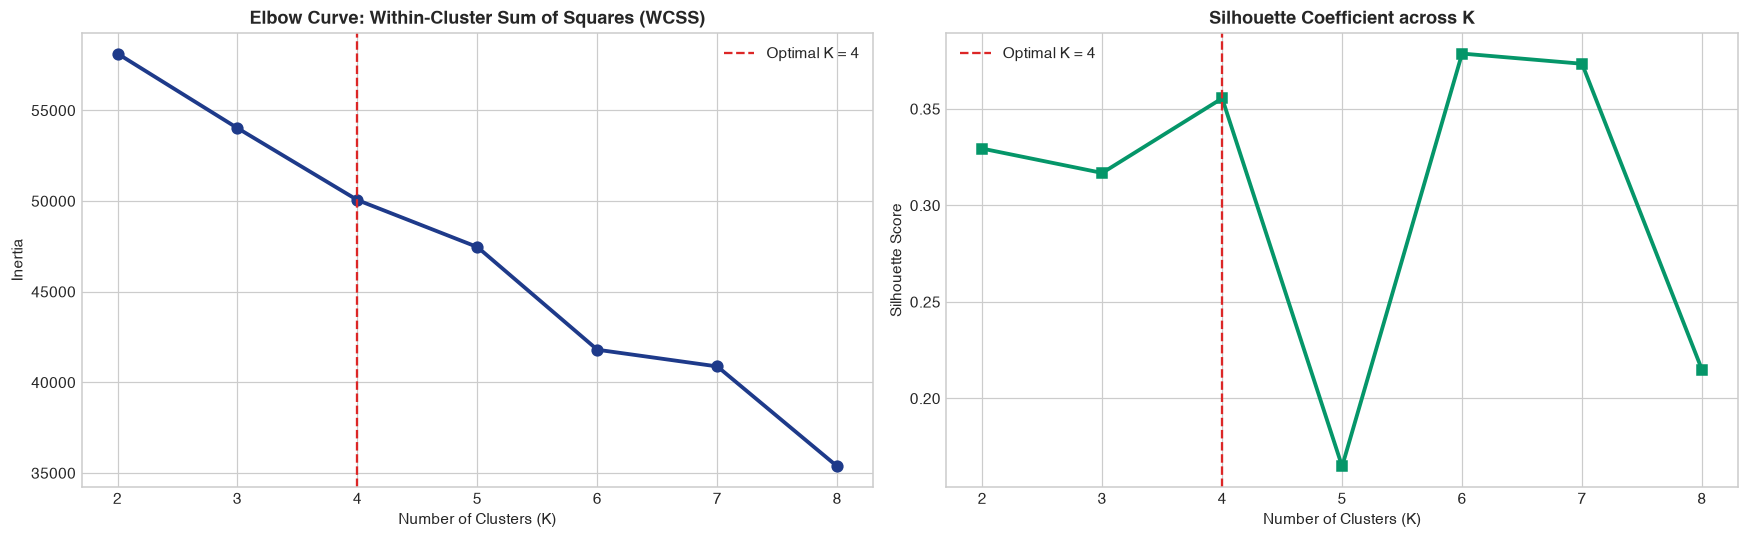

Optimal Cluster Count Selected: K = 4 (Silhouette Score: 0.3554)


In [5]:
# Step 5: Optimization Analysis for K in [2, 8]
k_range = range(2, 9)
inertias = []
silhouettes = []
davies_bouldin = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=15, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    davies_bouldin.append(davies_bouldin_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Elbow Curve
axes[0].plot(k_range, inertias, 'o-', color='#1e3a8a', linewidth=2.5, markersize=7)
axes[0].set_title('Elbow Curve: Within-Cluster Sum of Squares (WCSS)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].axvline(x=4, color='#dc2626', linestyle='--', label='Optimal K = 4')
axes[0].legend()

# Silhouette Score
axes[1].plot(k_range, silhouettes, 's-', color='#059669', linewidth=2.5, markersize=7)
axes[1].set_title('Silhouette Coefficient across K', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].axvline(x=4, color='#dc2626', linestyle='--', label='Optimal K = 4')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Optimal Cluster Count Selected: K = 4 (Silhouette Score: {silhouettes[2]:.4f})")


In [6]:
# Step 4: Fit K-Means and Hierarchical Clustering at K=4
km_final = KMeans(n_clusters=4, init='k-means++', n_init=25, random_state=42)
df_clean['kmeans_cluster'] = km_final.fit_predict(X_scaled)

agg_final = AgglomerativeClustering(n_clusters=4, linkage='ward')
df_clean['hierarchical_cluster'] = agg_final.fit_predict(X_scaled)

print(f"K-Means Silhouette Score (K=4): {silhouette_score(X_scaled, df_clean['kmeans_cluster']):.4f}")
print(f"Hierarchical Silhouette Score (K=4): {silhouette_score(X_scaled, df_clean['hierarchical_cluster']):.4f}")

# Cross-tabulation comparing cluster concordance
pd.crosstab(df_clean['kmeans_cluster'], df_clean['hierarchical_cluster'], rownames=['K-Means'], colnames=['Hierarchical'])


K-Means Silhouette Score (K=4): 0.3568
Hierarchical Silhouette Score (K=4): 0.3435


Hierarchical,0,1,2,3
K-Means,,,,
0,2,1536,0,0
1,40,0,0,0
2,84,1,0,0
3,51,39,95,152


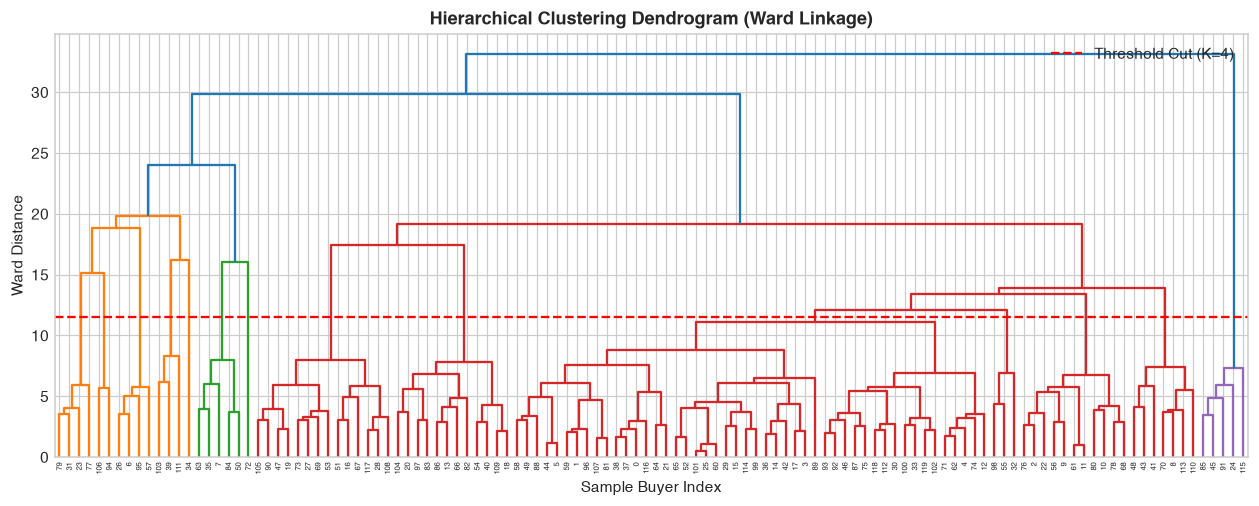

In [7]:
# Hierarchical Clustering Dendrogram (Ward Linkage - Subsample N=120)
plt.figure(figsize=(14, 5))
sample_idx = np.random.RandomState(42).choice(len(X_scaled), size=120, replace=False)
linked = linkage(X_scaled[sample_idx], method='ward')

dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=12, fontweight='bold')
plt.xlabel('Sample Buyer Index')
plt.ylabel('Ward Distance')
plt.axhline(y=11.5, color='red', linestyle='--', label='Threshold Cut (K=4)')
plt.legend()
plt.show()


## Step 6 – Cluster Interpretation & Recommended Buyer Segments

In accordance with the PRD specification, we map the four clusters to their target business archetypes:
- **C1: Global Investors:** Cross-border international buyers, investment-focused.
- **C2: First-Time Buyers:** Younger demographic, loan-dependent, personal dwelling focus.
- **C3: Corporate Buyers:** Entity-level buyers acquiring multiple units across residential & office.
- **C4: Luxury Investors:** High satisfaction ratings, large individual capital commitments.


In [8]:
# Step 6: Centroid Profiling and Segment Mapping
centroids = df_clean.groupby('kmeans_cluster').agg({
    'total_investment': 'mean',
    'units_purchased': 'mean',
    'age': 'mean',
    'satisfaction_score': 'mean',
    'loan_applied': lambda x: (x == 'Yes').mean(),
    'client_type_norm': lambda x: (x == 'Corporate').mean(),
    'country': lambda x: (x != 'USA').mean(),
    'acquisition_purpose_norm': lambda x: (x == 'Investment').mean()
})

# Archetype mapping logic
mapping = {}
# 1. Corporate: highest corporate ratio
c_corp = centroids['client_type_norm'].idxmax()
mapping[c_corp] = ('C3: Corporate Buyers', 'Companies purchasing multiple units')

rem = [c for c in centroids.index if c not in mapping]
# 2. Luxury: highest satisfaction score
c_lux = centroids.loc[rem, 'satisfaction_score'].idxmax()
mapping[c_lux] = ('C4: Luxury Investors', 'High satisfaction, large investments')

rem = [c for c in centroids.index if c not in mapping]
# 3. Global: highest international ratio
c_glob = centroids.loc[rem, 'country'].idxmax()
mapping[c_glob] = ('C1: Global Investors', 'Cross-border capital, investment purchases')

rem = [c for c in centroids.index if c not in mapping]
c_ft = rem[0]
mapping[c_ft] = ('C2: First-Time Buyers', 'Younger demographic, loan dependent')

df_clean['buyer_segment'] = df_clean['kmeans_cluster'].map(lambda x: mapping[x][0])
df_clean['characteristics'] = df_clean['kmeans_cluster'].map(lambda x: mapping[x][1])

# Summary Table
segment_summary = df_clean.groupby('buyer_segment').agg(
    Client_Count=('client_id', 'count'),
    Avg_Age=('age', 'mean'),
    Avg_Investment=('total_investment', 'mean'),
    Avg_Units=('units_purchased', 'mean'),
    Avg_Satisfaction=('satisfaction_score', 'mean'),
    Loan_Dependency_Pct=('loan_applied', lambda x: f"{(x == 'Yes').mean()*100:.1f}%"),
    International_Pct=('country', lambda x: f"{(x != 'USA').mean()*100:.1f}%")
).reset_index()

segment_summary['Avg_Age'] = segment_summary['Avg_Age'].round(1)
segment_summary['Avg_Investment'] = segment_summary['Avg_Investment'].apply(lambda x: f"${x:,.0f}")
segment_summary['Avg_Units'] = segment_summary['Avg_Units'].round(1)
segment_summary['Avg_Satisfaction'] = segment_summary['Avg_Satisfaction'].round(2)

print("PARCL BUYER SEGMENTATION SUMMARY TABLE:")
segment_summary


PARCL BUYER SEGMENTATION SUMMARY TABLE:


,buyer_segment,Client_Count,Avg_Age,Avg_Investment,Avg_Units,Avg_Satisfaction,Loan_Dependency_Pct,International_Pct
0,C1: Global Investors,337,54.2,"$1,236,373",3.6,2.95,36.5%,100.0%
1,C2: First-Time Buyers,1538,56.5,"$1,269,852",3.7,3.03,36.7%,0.0%
2,C3: Corporate Buyers,40,56.8,"$1,210,744",3.6,3.22,40.0%,100.0%
3,C4: Luxury Investors,85,55.8,"$1,207,423",3.5,3.22,38.8%,100.0%


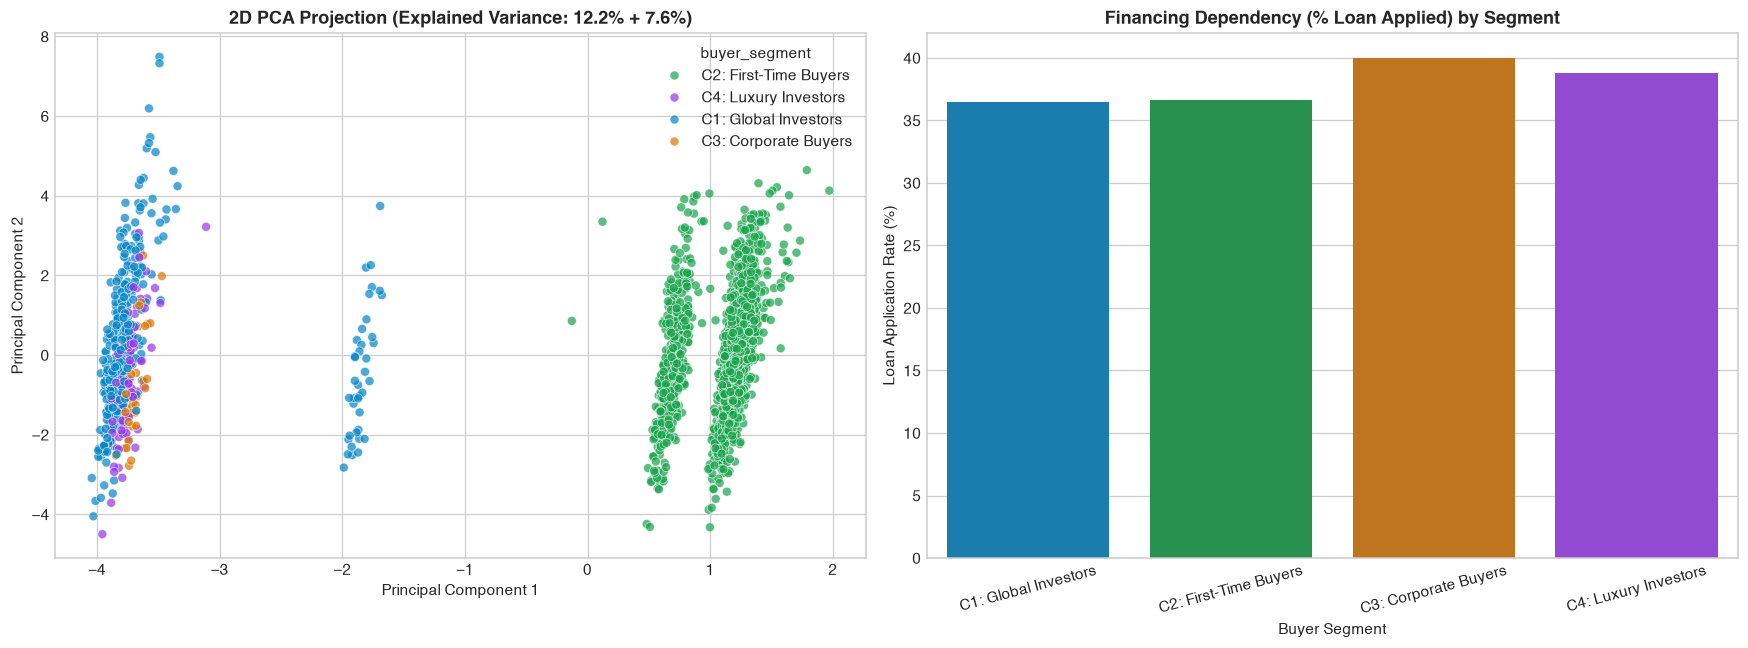

In [9]:
# 2D PCA Cluster Map & Segment Financing Rates
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df_clean['pca1'] = X_pca[:, 0]
df_clean['pca2'] = X_pca[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

palette = {
    'C1: Global Investors': '#0284c7',
    'C2: First-Time Buyers': '#16a34a',
    'C3: Corporate Buyers': '#d97706',
    'C4: Luxury Investors': '#9333ea'
}

sns.scatterplot(
    data=df_clean,
    x='pca1',
    y='pca2',
    hue='buyer_segment',
    palette=palette,
    alpha=0.7,
    s=35,
    ax=axes[0]
)
axes[0].set_title(f'2D PCA Projection (Explained Variance: {pca.explained_variance_ratio_[0]*100:.1f}% + {pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

# Financing Dependency by Segment
loan_rates = df_clean.groupby('buyer_segment')['loan_applied'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
sns.barplot(data=loan_rates, x='buyer_segment', y='loan_applied', palette=palette, ax=axes[1])
axes[1].set_title('Financing Dependency (% Loan Applied) by Segment', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Buyer Segment')
axes[1].set_ylabel('Loan Application Rate (%)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


## Strategic Recommendations for Parcl Co. Limited

### 1. **C1: Global Investors** (Cross-border capital, investment purchases)
- **Strategic Action:** Provide synthetic city-level real estate index trading on the Parcl protocol, removing cross-border title transfer frictions and offering automated currency conversion.

### 2. **C2: First-Time Buyers** (Younger demographic, loan dependent)
- **Strategic Action:** Embed instant digital mortgage pre-qualification calculators directly into the portal, reducing drop-off during underwriting review.

### 3. **C3: Corporate Buyers** (Companies purchasing multiple units)
- **Strategic Action:** Assign dedicated enterprise portfolio managers and provide institutional bulk-execution APIs with tiered fee discounts.

### 4. **C4: Luxury Investors** (High satisfaction, large investments)
- **Strategic Action:** Offer white-glove concierge advisory, off-market penthouse tranches, and private wealth syndication opportunities.
